# PRCP-1000: Portuguese Bank Marketing, Term Deposit Prediction

**Dataset:** bank-additional-full.csv (41,188 clients, 21 columns), direct phone-call campaigns of a Portuguese bank (May 2008 to November 2010).

**Tasks:**
1. Complete data analysis report
2. Predictive model to find which customer will buy the term deposit
3. Suggestions to the bank marketing team

The model comparison report and the challenges report are at the end of the notebook.

---
## Part 1: Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
%matplotlib inline

In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
print(df.dtypes.value_counts())
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

object     11
int64       5
float64     5
Name: count, dtype: int64
Total missing values: 0
Duplicate rows: 12


In [4]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.drop("y").tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


     count  percent
y                  
no   36548     88.7
yes   4640     11.3


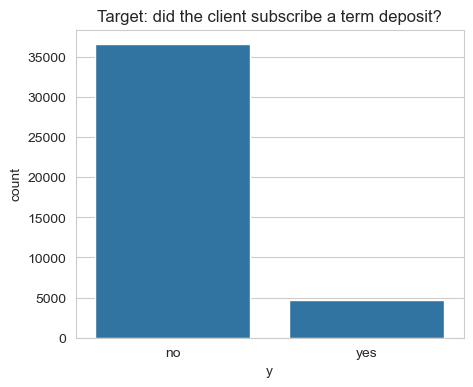

In [5]:
target_counts = df["y"].value_counts()
target_pct = (df["y"].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({"count": target_counts, "percent": target_pct}))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="y")
plt.title("Target: did the client subscribe a term deposit?")
plt.show()

**Observation:** The target is imbalanced: 88.7% of clients said no and only 11.3% said yes. A model that always predicts "no" would be 88.7% accurate but useless, so accuracy alone is not a good metric here. I will use ROC-AUC, PR-AUC, recall, precision and F1.

,unknown_count,percent
default,8597,20.9
education,1731,4.2
housing,990,2.4
loan,990,2.4
job,330,0.8
marital,80,0.2


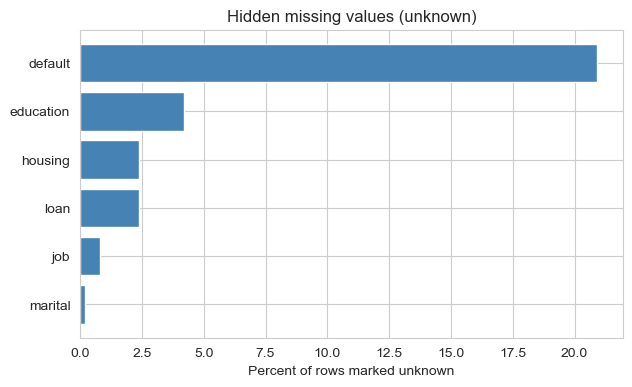

In [6]:
unknown_counts = (df[cat_cols] == "unknown").sum()
unknown_pct = (unknown_counts / len(df) * 100).round(1)
unknown_table = pd.DataFrame({"unknown_count": unknown_counts, "percent": unknown_pct})
unknown_table = unknown_table[unknown_table["unknown_count"] > 0].sort_values("percent", ascending=False)
display(unknown_table)

plt.figure(figsize=(7, 4))
plt.barh(unknown_table.index, unknown_table["percent"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("Percent of rows marked unknown")
plt.title("Hidden missing values (unknown)")
plt.show()

**Observation:** There are no null values, but "unknown" works as a hidden missing value. `default` has the most (20.9%), then `education` (4.2%), `housing` and `loan` (2.4% each). Clients with unknown default subscribe at 5.2% against 12.9% for "no", so "unknown" carries information. I will keep it as its own category instead of dropping rows or guessing a value.

In [7]:
df[num_cols].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [8]:
print("pdays = 999:", (df["pdays"] == 999).sum(), "rows")
print("Share:", round((df["pdays"] == 999).mean() * 100, 1), "%")
df["poutcome"].value_counts()

pdays = 999: 39673 rows
Share: 96.3 %


poutcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64

**Observation:** `pdays = 999` is not a real number of days; it means the client was never contacted before (96.3% of rows). Leaving it as a number would confuse distance-based models, so I will turn it into a yes/no flag later.

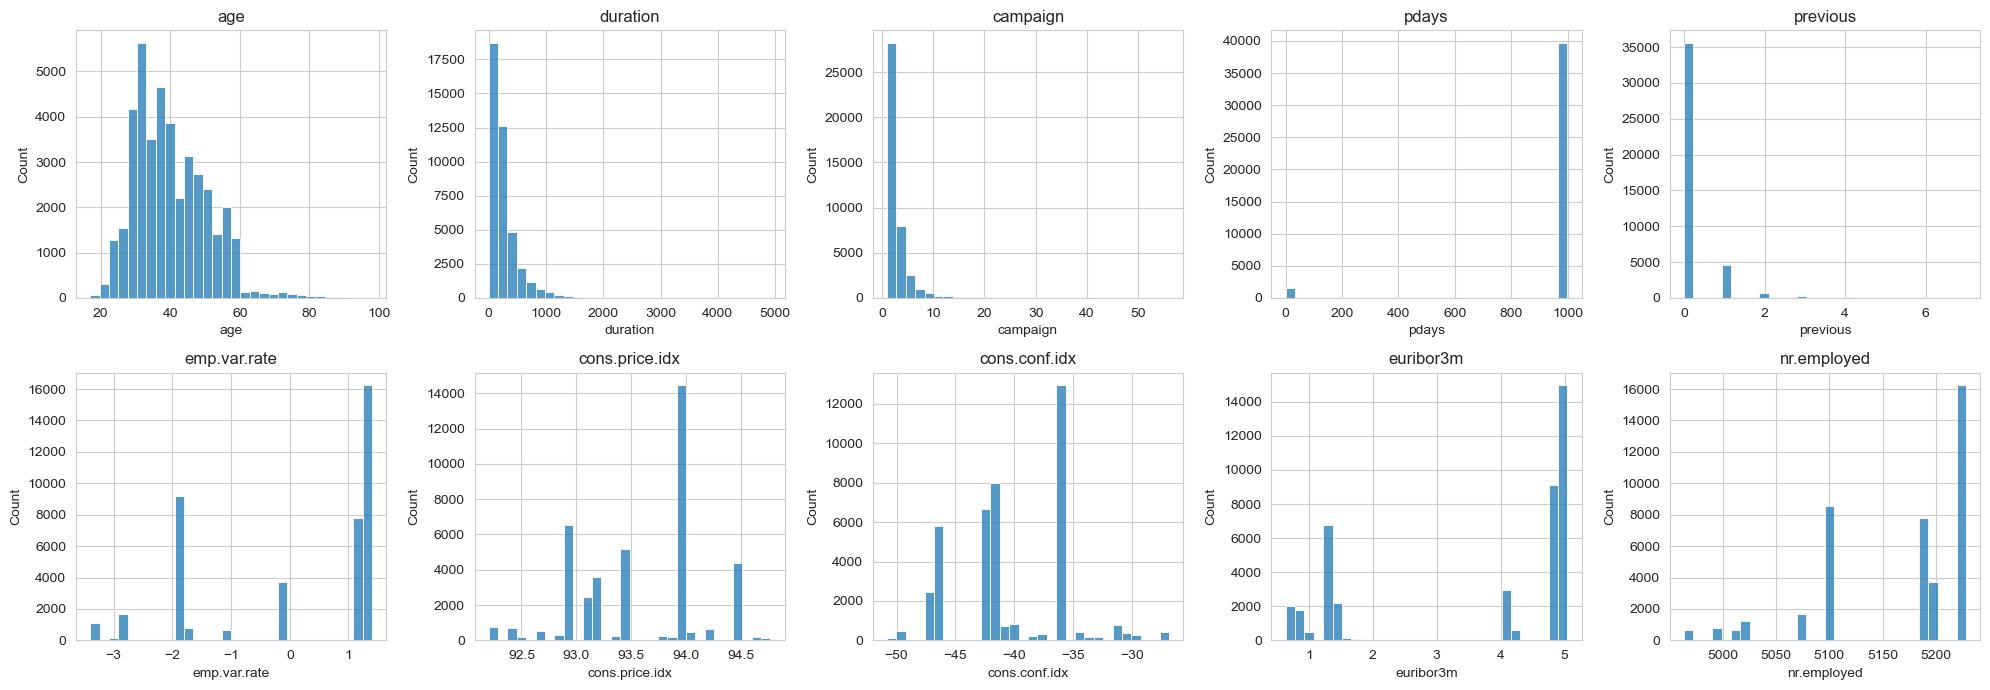

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

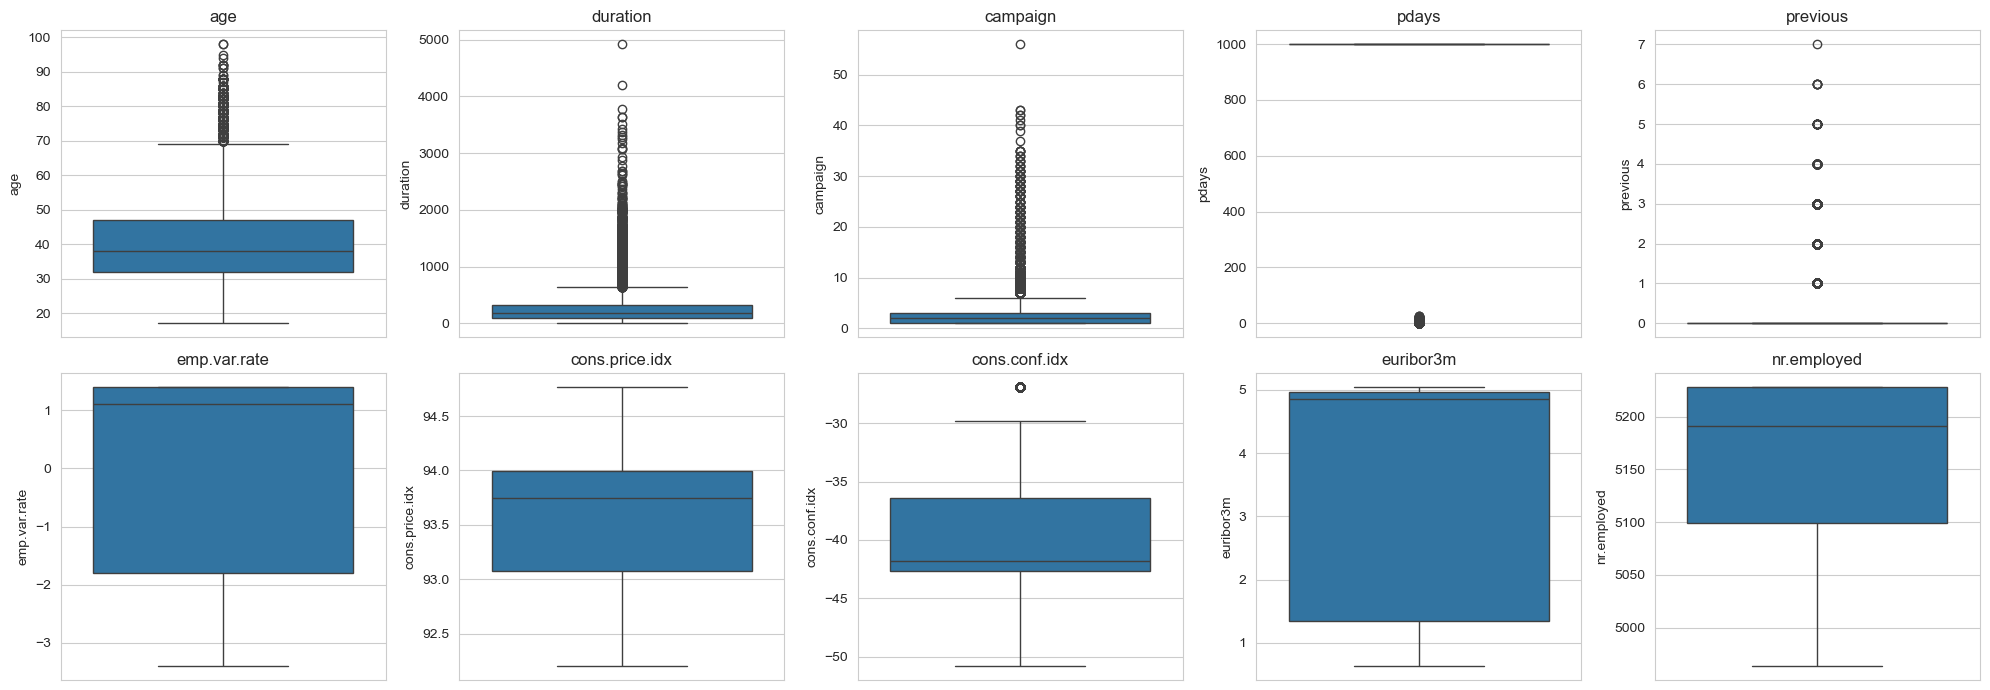

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Observation:** `duration`, `campaign` and `previous` are strongly right-skewed with many outliers (two calls lasted over 4,000 seconds and one client was contacted 56 times). The economic indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) take only a few distinct values because they are quarterly or monthly numbers repeated for many clients. I kept the outliers because they are real values and tree-based models handle them well.

In [11]:
df["y_num"] = (df["y"] == "yes").astype(int)

for col in cat_cols:
    rate = (df.groupby(col)["y_num"].mean() * 100).round(1).sort_values(ascending=False)
    print(col, "->", rate.to_dict())
    print()

job -> {'student': 31.4, 'retired': 25.2, 'unemployed': 14.2, 'admin.': 13.0, 'management': 11.2, 'unknown': 11.2, 'technician': 10.8, 'self-employed': 10.5, 'housemaid': 10.0, 'entrepreneur': 8.5, 'services': 8.1, 'blue-collar': 6.9}

marital -> {'unknown': 15.0, 'single': 14.0, 'divorced': 10.3, 'married': 10.2}

education -> {'illiterate': 22.2, 'unknown': 14.5, 'university.degree': 13.7, 'professional.course': 11.3, 'high.school': 10.8, 'basic.4y': 10.2, 'basic.6y': 8.2, 'basic.9y': 7.8}

default -> {'no': 12.9, 'unknown': 5.2, 'yes': 0.0}

housing -> {'yes': 11.6, 'no': 10.9, 'unknown': 10.8}

loan -> {'no': 11.3, 'yes': 10.9, 'unknown': 10.8}

contact -> {'cellular': 14.7, 'telephone': 5.2}

month -> {'mar': 50.5, 'dec': 48.9, 'sep': 44.9, 'oct': 43.9, 'apr': 20.5, 'aug': 10.6, 'jun': 10.5, 'nov': 10.1, 'jul': 9.0, 'may': 6.4}

day_of_week -> {'thu': 12.1, 'tue': 11.8, 'wed': 11.7, 'fri': 10.8, 'mon': 9.9}

poutcome -> {'success': 65.1, 'failure': 14.2, 'nonexistent': 8.8}



In [12]:
order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_stats = df.groupby("month")["y_num"].agg(["count", "mean"]).reindex(order)
month_stats["mean"] = (month_stats["mean"] * 100).round(1)
month_stats.columns = ["calls", "subscription_rate_%"]
month_stats

,calls,subscription_rate_%
month,,
mar,546,50.5
apr,2632,20.5
may,13769,6.4
jun,5318,10.5
jul,7174,9.0
aug,6178,10.6
sep,570,44.9
oct,718,43.9
nov,4101,10.1


**Observation:** The month matters a lot. March (50.5%), December (48.9%), September (44.9%) and October (43.9%) have very high subscription rates, but they have few calls (182 to 718). May has by far the most calls (13,769) and the lowest rate (6.4%). So the bank made most of its calls in the months where people were least likely to say yes. The high rates in the small months should be read with care because the samples are small.

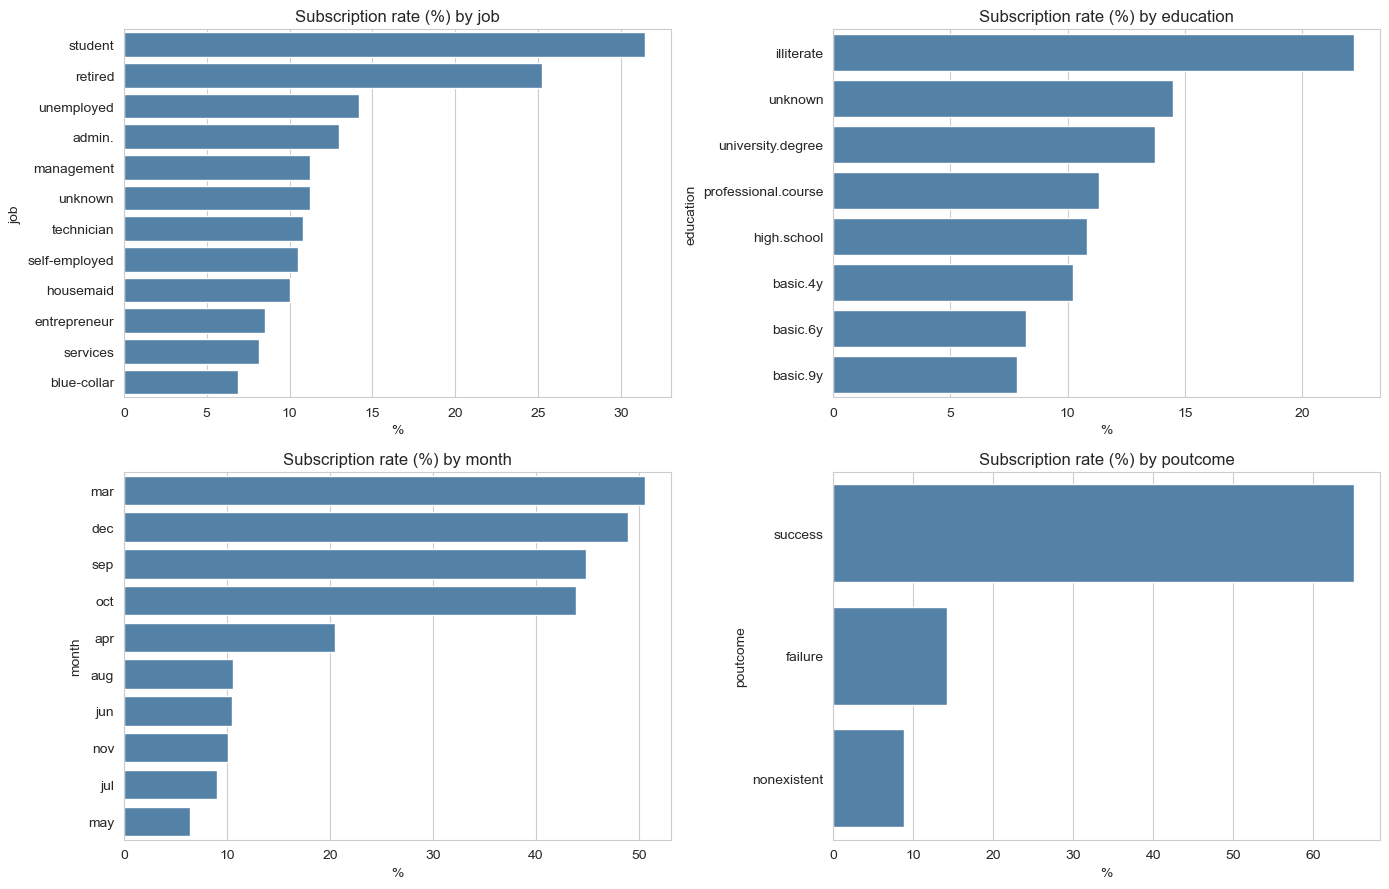

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flatten(), ["job", "education", "month", "poutcome"]):
    rate = df.groupby(col)["y_num"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="steelblue")
    ax.set_title(f"Subscription rate (%) by {col}")
    ax.set_xlabel("%")
plt.tight_layout()
plt.show()

**Observation:** Students (31.4%) and retired clients (25.2%) subscribe the most; blue-collar workers (6.9%) the least. Cellular contact works much better than telephone (14.7% vs 5.2%). If the previous campaign was a success, 65.1% subscribe again, against 8.8% for clients with no previous campaign. Day of week has little effect (9.9% on Monday to 12.1% on Thursday).

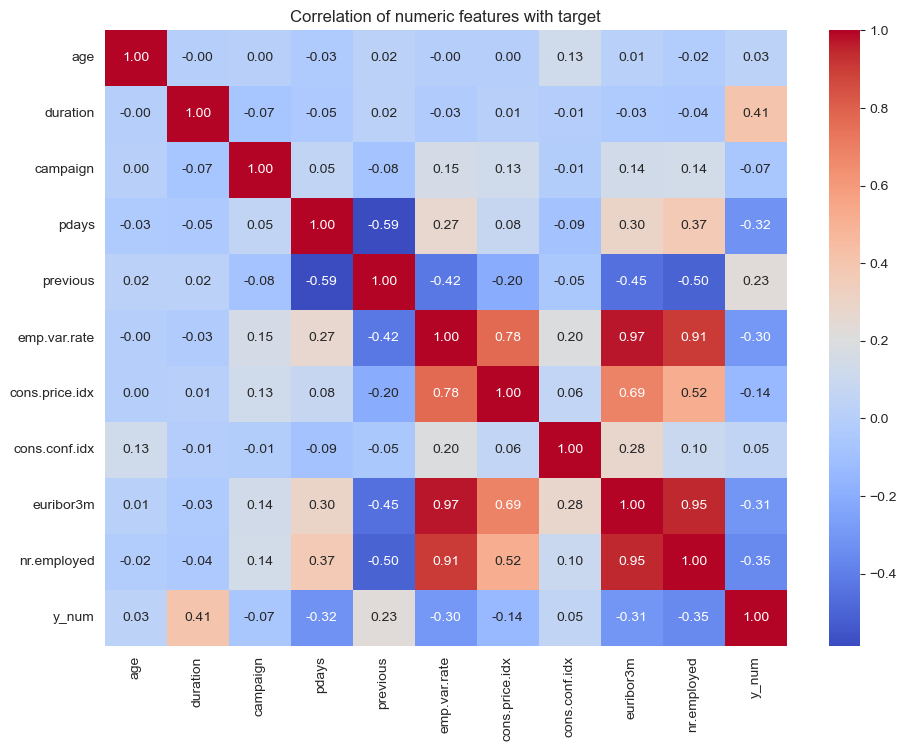

y_num             1.00
duration          0.41
previous          0.23
cons.conf.idx     0.05
age               0.03
campaign         -0.07
cons.price.idx   -0.14
emp.var.rate     -0.30
euribor3m        -0.31
pdays            -0.32
nr.employed      -0.35
Name: y_num, dtype: float64

In [14]:
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols + ["y_num"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation of numeric features with target")
plt.show()

df[num_cols + ["y_num"]].corr()["y_num"].round(2).sort_values(ascending=False)

In [15]:
df.groupby("y")[["age", "duration", "campaign", "euribor3m", "nr.employed"]].mean().round(1)

,age,duration,campaign,euribor3m,nr.employed
y,,,,,
no,39.9,220.8,2.6,3.8,5176.2
yes,40.9,553.2,2.1,2.1,5095.1


**Observation:** `duration` has the strongest correlation with the target (0.41), but it is only known after the call ends, so it cannot be used in a real prediction model (more on this in Part 2). Among usable features, `nr.employed` (-0.35), `pdays` (-0.32), `euribor3m` (-0.31) and `emp.var.rate` (-0.30) are the strongest. Clients who subscribed were reached when the euribor rate was lower (2.1 vs 3.8) and the number of employees was lower. `emp.var.rate`, `euribor3m` and `nr.employed` are highly correlated with each other, which matters for linear models.

In [16]:
# Does calling the same client again and again help?
df["campaign_group"] = pd.cut(df["campaign"], bins=[0, 1, 2, 3, 5, 10, 100],
                              labels=["1", "2", "3", "4-5", "6-10", "11+"])
campaign_stats = df.groupby("campaign_group")["y_num"].agg(["count", "mean"])
campaign_stats["mean"] = (campaign_stats["mean"] * 100).round(1)
campaign_stats.columns = ["clients", "subscription_rate_%"]
campaign_stats

,clients,subscription_rate_%
campaign_group,,
1,17642,13.0
2,10570,11.5
3,5341,10.7
4-5,4250,8.7
6-10,2516,6.3
11+,869,3.1


**Observation:** More calls do not mean more sales. The subscription rate falls from 13.0% at the first contact to 6.3% at 6-10 contacts and 3.1% after 11 contacts. Repeated calling to the same client has strongly diminishing returns.

In [17]:
df["age_group"] = pd.cut(df["age"], bins=[0, 25, 35, 45, 55, 65, 100],
                        labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"])
age_stats = df.groupby("age_group")["y_num"].agg(["count", "mean"])
age_stats["mean"] = (age_stats["mean"] * 100).round(1)
age_stats.columns = ["clients", "subscription_rate_%"]
age_stats

,clients,subscription_rate_%
age_group,,
<=25,1666,20.9
26-35,14847,11.7
36-45,12844,8.5
46-55,8249,8.7
56-65,2963,15.2
65+,619,46.8


**Observation:** The age effect is U-shaped. Young clients (25 or below) subscribe at 20.9% and older clients (56-65) at 15.2%, while the 36-55 group is lowest (around 8.5%). Clients over 65 subscribe at 46.8%, but there are only 619 of them.

In [18]:
prev_stats = df.groupby(df["pdays"] != 999)["y_num"].agg(["count", "mean"])
prev_stats["mean"] = (prev_stats["mean"] * 100).round(1)
prev_stats.index = ["Not contacted before", "Contacted before"]
prev_stats.columns = ["clients", "subscription_rate_%"]
prev_stats

,clients,subscription_rate_%
Not contacted before,39673,9.3
Contacted before,1515,63.8


**Observation:** Clients who were contacted in an earlier campaign subscribe at 63.8%, compared with 9.3% for new clients. Only 1,515 clients (3.7%) were contacted before, so this is a small but very valuable group.

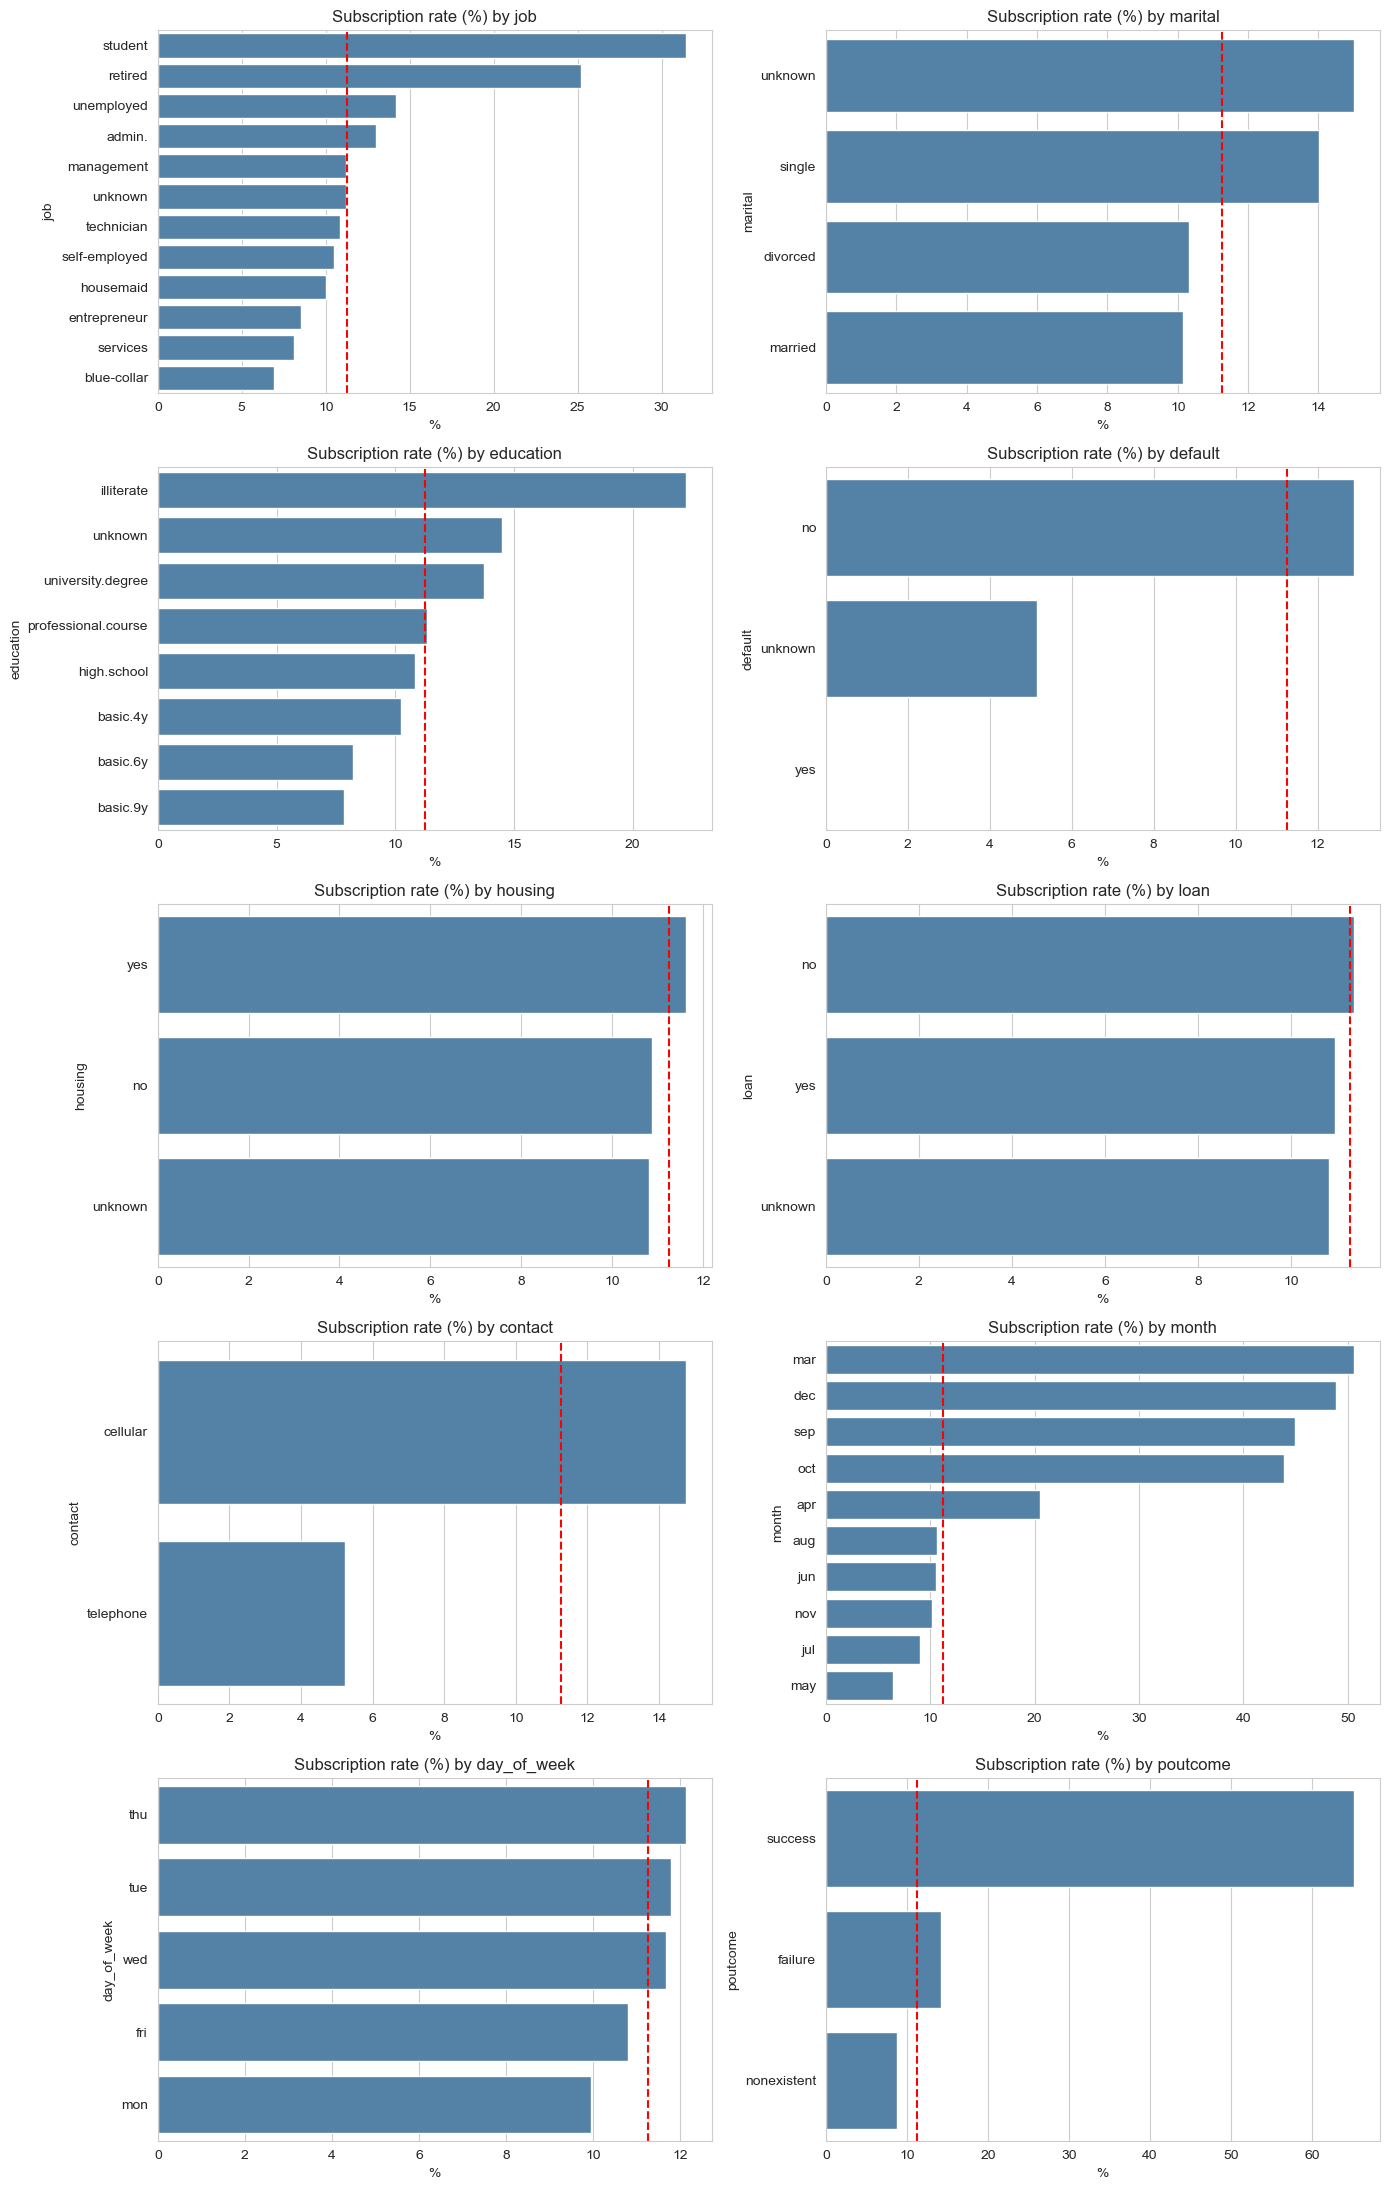

In [19]:
fig, axes = plt.subplots(5, 2, figsize=(14, 22))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)["y_num"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="steelblue")
    ax.axvline(df["y_num"].mean() * 100, color="red", linestyle="--")
    ax.set_title(f"Subscription rate (%) by {col}")
    ax.set_xlabel("%")
plt.tight_layout()
plt.show()

**Observation:** The red line is the overall subscription rate (11.3%). Month, contact type, poutcome and job show the biggest differences from the average. Housing loan, personal loan and day of week are close to the average, so they carry little signal on their own. Marital status shows a small difference (single 14.0%, married 10.2%). For `default`, only 3 clients are "yes" and none of them subscribed, so that category is too small to judge.

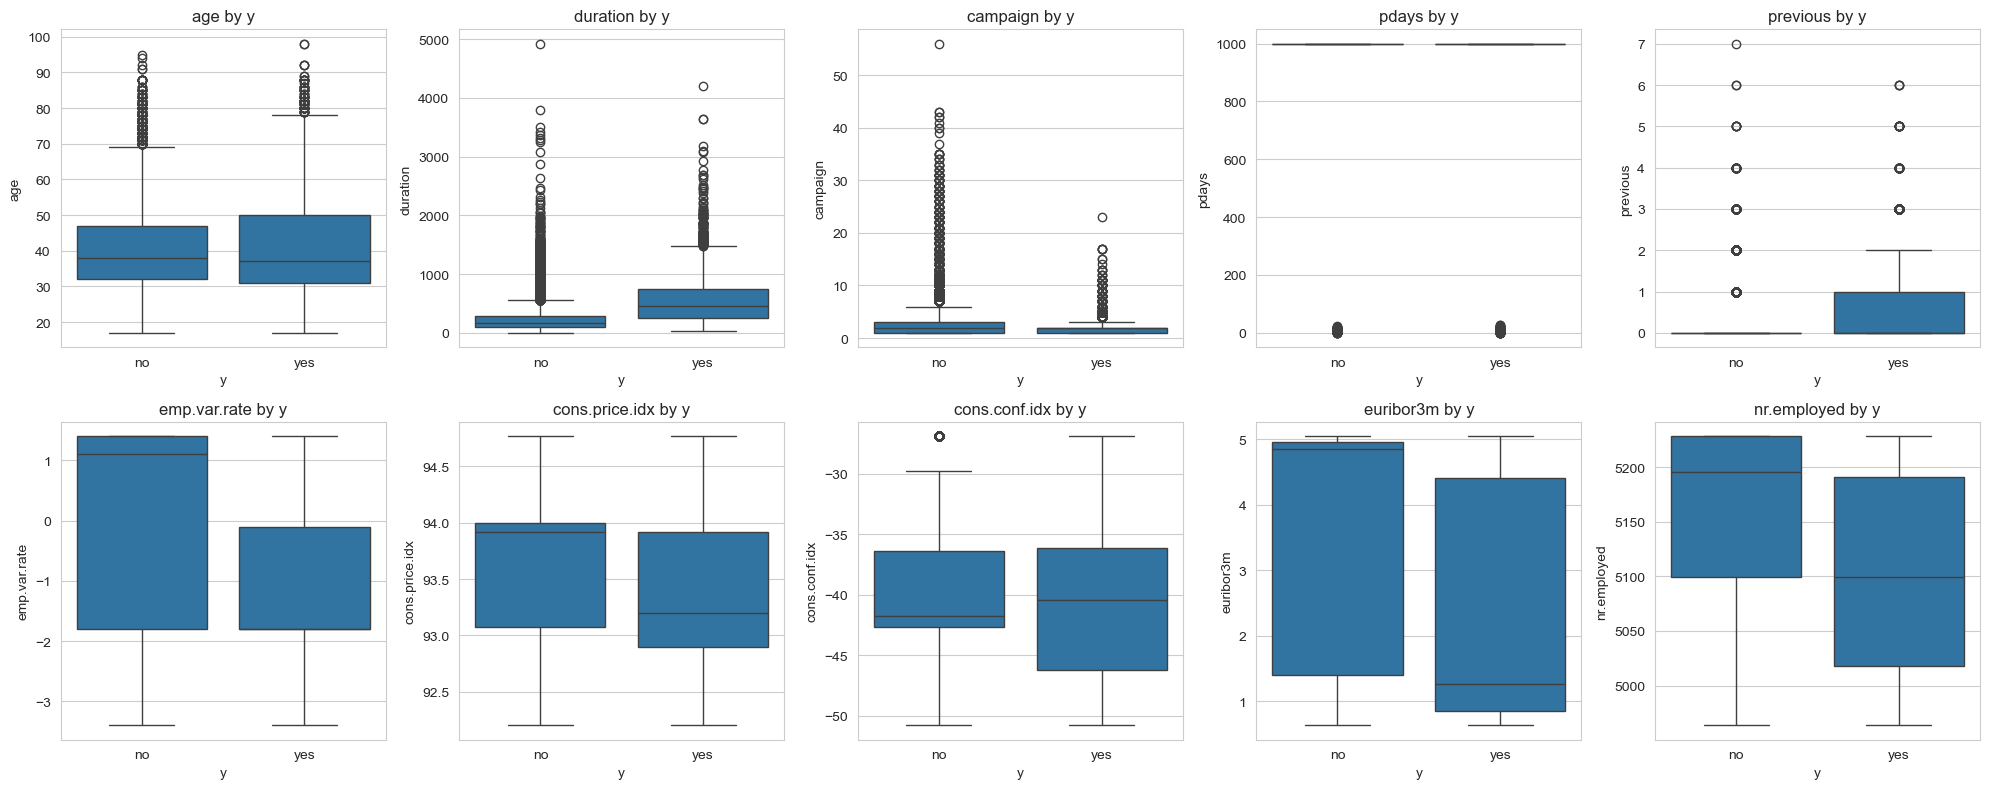

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df, x="y", y=col, ax=ax)
    ax.set_title(f"{col} by y")
plt.tight_layout()
plt.show()

**Observation:** Clients who said yes had much longer calls (average 553 s vs 221 s) and were contacted fewer times in this campaign (2.1 vs 2.6). They were also reached when `euribor3m` and `nr.employed` were lower. Age looks similar for both groups, so age alone does not separate them.

---
## Part 2: Data Cleaning and Preprocessing

In [21]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows before:", before, "| after:", len(df), "| removed:", before - len(df))

Rows before: 41188 | after: 41176 | removed: 12


**Decision:** 12 exact duplicate rows were removed (41,188 to 41,176). Duplicates can leak into both train and test sets and make results look better than they are.

In [22]:
# pdays = 999 means "not contacted before": turn it into a flag and set pdays to 0 for those rows
df["previously_contacted"] = (df["pdays"] != 999).astype(int)
df["pdays"] = df["pdays"].replace(999, 0)
df[["pdays", "previously_contacted"]].describe().round(2)

,pdays,previously_contacted
count,41176.00,41176.00
mean,0.22,0.04
std,1.35,0.19
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,0.00,0.00
max,27.00,1.00


**Decision:** `pdays = 999` was a placeholder, not a real number of days. I created a `previously_contacted` flag (1 if contacted before, else 0) and set `pdays` to 0 for the placeholder rows, so the model is not misled by a value of 999.

In [23]:
# Target and two feature sets
y = df["y_num"]
X_all = df.drop(columns=["y", "y_num", "campaign_group", "age_group"])   # with duration (benchmark only)
X_real = X_all.drop(columns=["duration"])                              # realistic model (no duration)

print("Benchmark features:", X_all.shape[1])
print("Realistic features:", X_real.shape[1])
print("Dropped from realistic set:", [c for c in X_all.columns if c not in X_real.columns])

Benchmark features: 21
Realistic features: 20
Dropped from realistic set: ['duration']


**Decision (data leakage):** `duration` is the length of the call, which is only known after the call ends, and the call result is known at that moment. The dataset description itself says it should be discarded for a realistic model. I will build the final model **without** `duration`, and use a second model **with** `duration` only as a benchmark to show how much it inflates the score. The helper columns `campaign_group` and `age_group` made for EDA are also dropped.

In [24]:
# One stratified split, shared by every model and both feature sets
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

X_train, X_test = X_real.loc[train_idx], X_real.loc[test_idx]
Xb_train, Xb_test = X_all.loc[train_idx], X_all.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Yes rate in train:", round(y_train.mean() * 100, 2), "% | in test:", round(y_test.mean() * 100, 2), "%")

Train: (32940, 20) | Test: (8236, 20)
Yes rate in train: 11.27 % | in test: 11.27 %



**Decision:** 80/20 stratified split, so both sets keep the same 11.27% yes rate. Every model and both feature sets use the same rows, which makes the comparison fair. The test set is not touched until the final evaluation.

In [25]:
def make_preprocessor(X):
    num = X.select_dtypes(include="number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)
    ])

def make_pipeline(model, X):
    return Pipeline([("prep", make_preprocessor(X)), ("model", model)])

n_num = X_real.select_dtypes(include="number").shape[1]
n_cat = X_real.select_dtypes(exclude="number").shape[1]
print("Numeric columns:", n_num, "| Categorical columns:", n_cat)

Numeric columns: 10 | Categorical columns: 10


**Decisions:**
- Categorical columns are one-hot encoded. I did not use label encoding because job, marital status or month have no real numeric order, and a number code would create a fake order. "unknown" becomes its own category.
- Numeric columns are standardised (needed for Logistic Regression, harmless for trees).
- Scaling and encoding are placed inside a `Pipeline`. During cross-validation they are fitted only on the training folds, so no information leaks from the validation fold.
- `handle_unknown="ignore"` keeps the pipeline from failing if a new category appears in future data.

---
## Part 3: Predictive Model (Task 2)

In [26]:
models = {
    "Dummy (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
print("Models:", list(models.keys()))

Models: ['Dummy (baseline)', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'Hist Gradient Boosting']


**Models compared:** a dummy baseline (always predicts "no"), Logistic Regression (simple linear model), Decision Tree (single tree), Random Forest and Histogram Gradient Boosting (two ensemble methods). `class_weight="balanced"` makes mistakes on the rare "yes" class cost more, which handles the 11.3% imbalance. All models run inside the same preprocessing pipeline.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "avg_precision": "average_precision",
           "recall": "recall", "precision": "precision", "f1": "f1"}

cv_rows = []
for name, model in models.items():
    start = time.time()
    res = cross_validate(make_pipeline(model, X_train), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    for metric in scoring:
        row[metric] = f"{res['test_' + metric].mean():.3f} +/- {res['test_' + metric].std():.3f}"
    row["time_sec"] = round(time.time() - start, 1)
    cv_rows.append(row)

cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table

,roc_auc,avg_precision,recall,precision,f1,time_sec
Model,,,,,,
Dummy (baseline),0.500 +/- 0.000,0.113 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,5.8
Logistic Regression,0.791 +/- 0.008,0.446 +/- 0.013,0.622 +/- 0.013,0.353 +/- 0.007,0.450 +/- 0.008,1.8
Decision Tree,0.780 +/- 0.012,0.419 +/- 0.015,0.610 +/- 0.037,0.354 +/- 0.040,0.445 +/- 0.024,1.4
Random Forest,0.794 +/- 0.008,0.464 +/- 0.016,0.584 +/- 0.015,0.432 +/- 0.010,0.497 +/- 0.010,16.7
Hist Gradient Boosting,0.800 +/- 0.008,0.467 +/- 0.015,0.624 +/- 0.014,0.385 +/- 0.011,0.476 +/- 0.012,4.2


**5-fold cross-validation on the training data** (mean +/- standard deviation). The dummy baseline has a ROC-AUC of 0.5, meaning no skill, so every real model adds value. The standard deviations are small, so results are stable across folds. Accuracy is not used for comparison because of the class imbalance.

In [28]:
def evaluate(pipe, Xtr, ytr, Xte, yte, threshold=0.5):
    pipe.fit(Xtr, ytr)
    proba = pipe.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred),
        "F1": f1_score(yte, pred),
        "ROC-AUC": roc_auc_score(yte, proba),
        "PR-AUC": average_precision_score(yte, proba),
    }, proba

test_rows = {}
test_proba = {}
for name, model in models.items():
    metrics, proba = evaluate(make_pipeline(model, X_train), X_train, y_train, X_test, y_test)
    test_rows[name] = metrics
    test_proba[name] = proba

test_table = pd.DataFrame(test_rows).T.round(3)
test_table

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy (baseline),0.887,0.000,0.000,0.000,0.500,0.113
Logistic Regression,0.830,0.359,0.645,0.462,0.800,0.446
Decision Tree,0.847,0.390,0.637,0.484,0.801,0.460
Random Forest,0.872,0.450,0.611,0.519,0.806,0.485
Hist Gradient Boosting,0.849,0.397,0.654,0.494,0.817,0.490


**Test-set results (threshold 0.50).** The dummy model reaches 88.7% accuracy but finds no buyers (recall 0), which proves that accuracy is misleading here. The balanced models have lower accuracy than the dummy because they deliberately flag more clients as likely buyers, and they find roughly 61% to 65% of the real buyers.

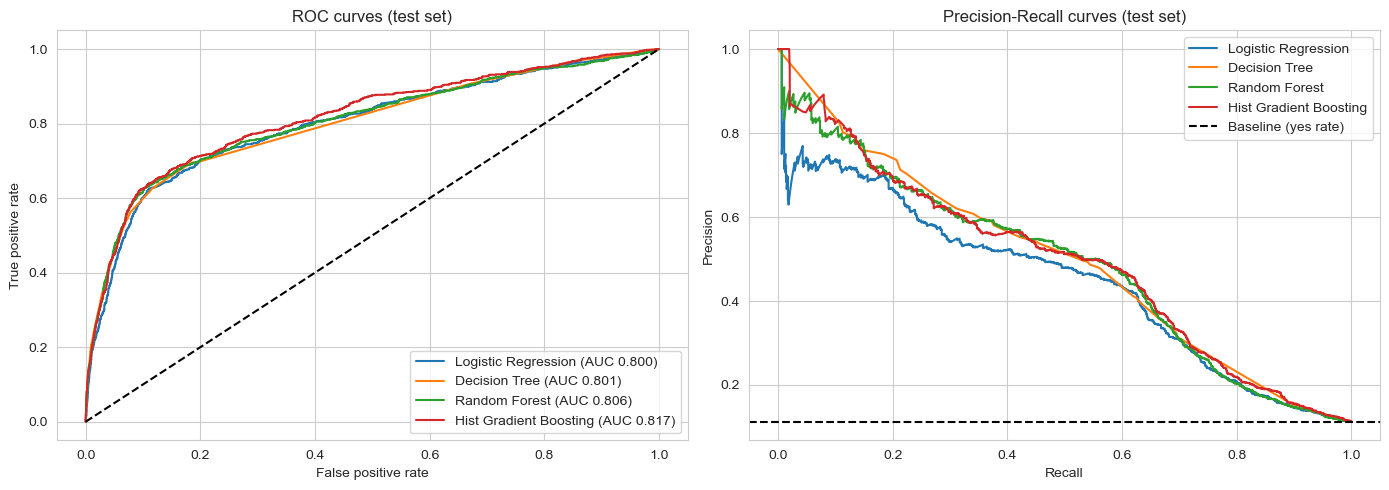

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, proba in test_proba.items():
    if name.startswith("Dummy"):
        continue
    fpr, tpr, _ = roc_curve(y_test, proba)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")
    axes[1].plot(rec, prec, label=name)
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curves (test set)")
axes[0].legend()
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Baseline (yes rate)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curves (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Observation:** All models are clearly above the random line, and the curves are close to each other, so the choice of algorithm matters less than the choice of features and threshold. The precision-recall curves are far above the baseline (the 11.3% yes rate).

In [30]:
# Benchmark: same models WITH duration (not realistic, only to show the leakage effect)
bench_rows = {}
for name, model in models.items():
    if name.startswith("Dummy"):
        continue
    metrics, _ = evaluate(make_pipeline(model, Xb_train), Xb_train, y_train, Xb_test, y_test)
    bench_rows[name] = {"ROC-AUC with duration": metrics["ROC-AUC"],
                        "ROC-AUC without duration": test_table.loc[name, "ROC-AUC"]}

bench_table = pd.DataFrame(bench_rows).T.round(3)
bench_table["difference"] = (bench_table["ROC-AUC with duration"] - bench_table["ROC-AUC without duration"]).round(3)
bench_table

,ROC-AUC with duration,ROC-AUC without duration,difference
Logistic Regression,0.940,0.800,0.140
Decision Tree,0.941,0.801,0.140
Random Forest,0.950,0.806,0.144
Hist Gradient Boosting,0.951,0.817,0.134


**Why `duration` was removed:** adding it raises ROC-AUC by about 0.14 for every model (from roughly 0.80 to roughly 0.95). That looks great, but it is not real: the call length is only known after the call, and by then the result is almost decided. A model using it could not be used to choose whom to call. The final model therefore does not use `duration`.

**Hyperparameter tuning:** Random Forest and Gradient Boosting were tuned with randomized search (10 random combinations each, 3-fold cross-validation on the training data, scored by ROC-AUC). The test set is not used for tuning. This cell can take a few minutes.

In [31]:
tuning_setup = {
    "Hist Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"model__learning_rate": [0.03, 0.05, 0.1, 0.2],
         "model__max_depth": [3, 5, 7, None],
         "model__max_leaf_nodes": [15, 31, 63],
         "model__min_samples_leaf": [20, 50, 100],
         "model__l2_regularization": [0, 0.1, 1, 10],
         "model__max_iter": [100, 200, 300]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
        {"model__n_estimators": [150, 250],
         "model__max_depth": [8, 12, 16, None],
         "model__min_samples_leaf": [3, 5, 10, 20],
         "model__max_features": ["sqrt", 0.3]}),
}

tuned = {}
for name, (model, grid) in tuning_setup.items():
    start = time.time()
    search = RandomizedSearchCV(make_pipeline(model, X_train), grid, n_iter=10, scoring="roc_auc",
                                cv=3, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"{name}: best CV ROC-AUC = {search.best_score_:.4f} | time {time.time() - start:.0f}s")
    print("   best params:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})

Hist Gradient Boosting: best CV ROC-AUC = 0.7995 | time 18s
   best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 300, 'max_depth': 7, 'learning_rate': 0.05, 'l2_regularization': 1}
Random Forest: best CV ROC-AUC = 0.7985 | time 95s
   best params: {'n_estimators': 150, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': 8}


In [32]:
tuned_rows = {}
for name, search in tuned.items():
    metrics, proba = evaluate(search.best_estimator_, X_train, y_train, X_test, y_test)
    tuned_rows[name + " (tuned)"] = metrics
    test_proba[name + " (tuned)"] = proba

tuned_table = pd.DataFrame(tuned_rows).T.round(3)
comparison = pd.concat([test_table.drop("Dummy (baseline)"), tuned_table])
comparison.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Hist Gradient Boosting,0.849,0.397,0.654,0.494,0.817,0.490
Random Forest (tuned),0.857,0.413,0.637,0.501,0.815,0.490
Hist Gradient Boosting (tuned),0.846,0.393,0.664,0.493,0.813,0.486
Random Forest,0.872,0.450,0.611,0.519,0.806,0.485
Decision Tree,0.847,0.390,0.637,0.484,0.801,0.460
Logistic Regression,0.830,0.359,0.645,0.462,0.800,0.446


**Observation:** Tuning changed the test results only slightly, which suggests the models were already close to the limit of what these 20 features can give. The final model is chosen from all models, tuned or not, by test ROC-AUC (ties broken by PR-AUC).

In [33]:
ranked = comparison.sort_values(["ROC-AUC", "PR-AUC"], ascending=False)
best_name = ranked.index[0]
print("Best model on the test set (by ROC-AUC, ties broken by PR-AUC):", best_name)

base_name = best_name.replace(" (tuned)", "")
if best_name.endswith("(tuned)"):
    final_model = tuned[base_name].best_estimator_
else:
    final_model = make_pipeline(models[base_name], X_train)
final_model.fit(X_train, y_train)
final_proba = final_model.predict_proba(X_test)[:, 1]
print("Final model test ROC-AUC:", round(roc_auc_score(y_test, final_proba), 3))

Best model on the test set (by ROC-AUC, ties broken by PR-AUC): Hist Gradient Boosting
Final model test ROC-AUC: 0.817


In [34]:
# Choose the decision threshold using out-of-fold predictions on the TRAIN data only (no peeking at test)
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.05)
thr_rows = []
for t in thresholds:
    p = (oof >= t).astype(int)
    thr_rows.append({"threshold": round(t, 2),
                     "precision": precision_score(y_train, p, zero_division=0),
                     "recall": recall_score(y_train, p),
                     "f1": f1_score(y_train, p)})
thr_table = pd.DataFrame(thr_rows).round(3)
best_threshold = float(thr_table.loc[thr_table["f1"].idxmax(), "threshold"])
print("Best threshold by F1 (train, out-of-fold):", best_threshold)
thr_table

Best threshold by F1 (train, out-of-fold): 0.7


,threshold,precision,recall,f1
0,0.10,0.113,0.999,0.204
1,0.15,0.116,0.989,0.208
2,0.20,0.129,0.956,0.227
3,0.25,0.150,0.901,0.257
4,0.30,0.182,0.830,0.299
5,0.35,0.228,0.756,0.350
6,0.40,0.292,0.689,0.410
7,0.45,0.345,0.646,0.450
8,0.50,0.385,0.624,0.476
9,0.55,0.415,0.600,0.491


**Threshold choice:** the default threshold of 0.50 is not necessarily best. A low threshold finds almost every buyer but most calls are wasted; a high threshold gives accurate calls but misses many buyers. The threshold was chosen on out-of-fold predictions from the training data (so the test set stays untouched). F1 is almost flat between thresholds 0.55 and 0.75, so the bank can move within this range depending on the cost of a call versus the value of a new deposit.

              precision    recall  f1-score   support

          no      0.945     0.922     0.933      7308
         yes      0.484     0.579     0.527       928

    accuracy                          0.883      8236
   macro avg      0.715     0.750     0.730      8236
weighted avg      0.893     0.883     0.888      8236



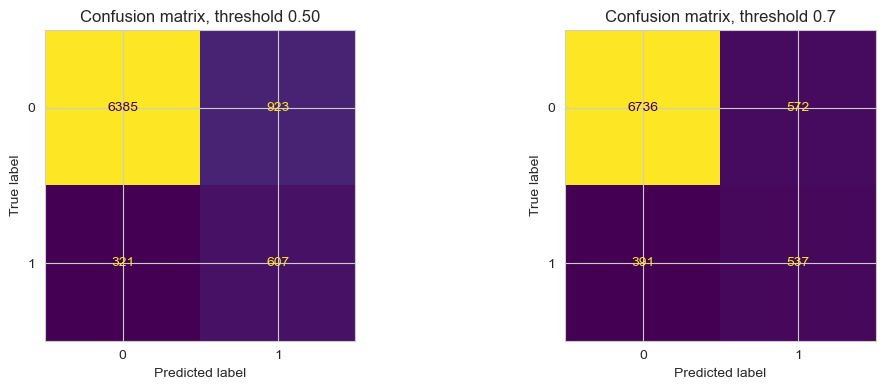

In [35]:
final_pred = (final_proba >= best_threshold).astype(int)
print(classification_report(y_test, final_pred, target_names=["no", "yes"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (final_proba >= 0.5).astype(int), ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix, threshold 0.50")
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, ax=axes[1], colorbar=False)
axes[1].set_title(f"Confusion matrix, threshold {best_threshold}")
plt.tight_layout()
plt.show()

**How to read this:** for the "yes" class, *precision* is the share of predicted buyers who really subscribed, and *recall* is the share of real buyers the model found. The higher threshold trades some recall for better precision, so fewer calls are wasted.

In [36]:
# Gains table: if the bank calls clients in order of predicted probability, how many buyers does it reach?
gains = pd.DataFrame({"proba": final_proba, "bought": y_test.values}).sort_values("proba", ascending=False).reset_index(drop=True)
gains["decile"] = pd.qcut(gains.index, 10, labels=False) + 1
decile_table = gains.groupby("decile").agg(clients=("bought", "size"), buyers=("bought", "sum"))
decile_table["buy_rate_%"] = (decile_table["buyers"] / decile_table["clients"] * 100).round(1)
decile_table["cum_buyers_captured_%"] = (decile_table["buyers"].cumsum() / decile_table["buyers"].sum() * 100).round(1)
decile_table["lift"] = (decile_table["buy_rate_%"] / (y_test.mean() * 100)).round(2)
decile_table

,clients,buyers,buy_rate_%,cum_buyers_captured_%,lift
decile,,,,,
1,824,432,52.4,46.6,4.65
2,824,184,22.3,66.4,1.98
3,823,69,8.4,73.8,0.75
4,824,51,6.2,79.3,0.55
5,823,50,6.1,84.7,0.54
6,824,35,4.2,88.5,0.37
7,823,30,3.6,91.7,0.32
8,824,29,3.5,94.8,0.31
9,823,28,3.4,97.8,0.30


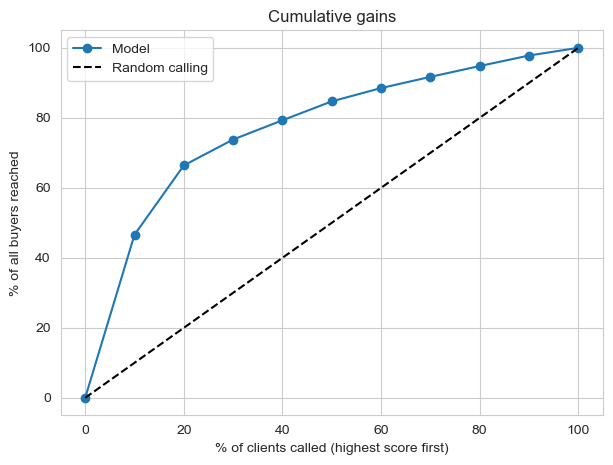

Calling only the top 20% of clients reaches 66.4% of all buyers.
Calling only the top 30% of clients reaches 73.8% of all buyers.


In [37]:
plt.figure(figsize=(7, 5))
x = np.arange(0, 11) * 10
plt.plot(x, [0] + decile_table["cum_buyers_captured_%"].tolist(), marker="o", label="Model")
plt.plot(x, x, "k--", label="Random calling")
plt.xlabel("% of clients called (highest score first)")
plt.ylabel("% of all buyers reached")
plt.title("Cumulative gains")
plt.legend()
plt.show()

top20 = decile_table.loc[2, "cum_buyers_captured_%"]
top30 = decile_table.loc[3, "cum_buyers_captured_%"]
print(f"Calling only the top 20% of clients reaches {top20}% of all buyers.")
print(f"Calling only the top 30% of clients reaches {top30}% of all buyers.")

**Business view:** a lift above 1 means a group buys more often than average. The highest-scored deciles have by far the highest lift, so ranking clients by model score gives a much better call list than calling at random. The printed lines above show how many buyers the bank would reach by calling only the top 20% or 30% of clients.

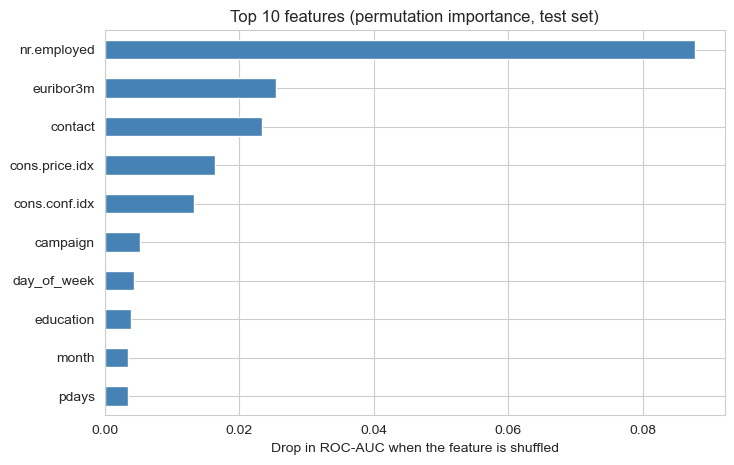

Most important features: nr.employed, euribor3m, contact, cons.price.idx, cons.conf.idx


nr.employed       0.0878
euribor3m         0.0255
contact           0.0235
cons.price.idx    0.0163
cons.conf.idx     0.0132
campaign          0.0053
day_of_week       0.0044
education         0.0040
month             0.0035
pdays             0.0035
dtype: float64

In [38]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importance.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title("Top 10 features (permutation importance, test set)")
plt.show()

print("Most important features:", ", ".join(importance.head(5).index))
importance.head(10).round(4)

**How to read this:** the chart shows how much the model's ROC-AUC drops when a feature is shuffled, so a longer bar means the model relies on that feature more. The economic indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) are highly correlated with each other (0.91 to 0.97), so permutation importance can split their credit and should be read as a group.

In [39]:
best_row = comparison.loc[best_name]
print("FINAL MODEL SUMMARY")
print("-" * 50)
print("Model            :", best_name)
print("Features used    :", X_train.shape[1], "(duration excluded)")
print(f"ROC-AUC          : {best_row['ROC-AUC']:.3f}")
print(f"PR-AUC           : {best_row['PR-AUC']:.3f}  (random baseline = {y_test.mean():.3f})")
final_p = (final_proba >= best_threshold).astype(int)
print(f"At threshold {best_threshold}: precision {precision_score(y_test, final_p):.3f}, recall {recall_score(y_test, final_p):.3f}, F1 {f1_score(y_test, final_p):.3f}")
print("Top 3 features   :", ", ".join(importance.head(3).index))

FINAL MODEL SUMMARY
--------------------------------------------------
Model            : Hist Gradient Boosting
Features used    : 20 (duration excluded)
ROC-AUC          : 0.817
PR-AUC           : 0.490  (random baseline = 0.113)
At threshold 0.7: precision 0.484, recall 0.579, F1 0.527
Top 3 features   : nr.employed, euribor3m, contact


---
## Model Comparison Report

In [40]:
from IPython.display import Markdown, display

def to_md(table, index_name="Model"):
    cols = [index_name] + list(table.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in table.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [f"{v:.3f}" for v in row.values]) + " |")
    return "\n".join(lines)

def family(name):
    return name.replace(" (tuned)", "")

ranked = comparison.sort_values(["ROC-AUC", "PR-AUC"], ascending=False)
# runner-up = best model from a different algorithm family
second_name = [n for n in ranked.index if family(n) != family(best_name)][0]
gap = ranked.loc[best_name, "ROC-AUC"] - ranked.loc[second_name, "ROC-AUC"]
avg_gain = bench_table["difference"].mean()
final_p = (final_proba >= best_threshold).astype(int)

report = f"""
### Model Comparison Report

**Setup.** {len(models) - 1} model types were compared with a dummy baseline: Logistic Regression, Decision Tree, Random Forest and Histogram Gradient Boosting. Random Forest and Gradient Boosting were also tuned with randomized search. All models use the same stratified 80/20 split, the same preprocessing pipeline and class weights to handle the 11.3% positive rate. Models were first compared with 5-fold cross-validation on the training data and then once on the untouched test set.

**Test-set results (threshold 0.50).**

{to_md(ranked)}

**Best model: {best_name}** with ROC-AUC {ranked.loc[best_name, "ROC-AUC"]:.3f} and PR-AUC {ranked.loc[best_name, "PR-AUC"]:.3f} (a random model would get a PR-AUC of {y_test.mean():.3f}). The best model from a different algorithm family is {second_name}, only {gap:.3f} ROC-AUC behind, so the leading models are close and the choice also depends on speed and simplicity.

**Decision threshold.** Using out-of-fold predictions on the training data, the best F1 was reached at a threshold of {best_threshold}. On the test set this gives precision {precision_score(y_test, final_p):.3f}, recall {recall_score(y_test, final_p):.3f} and F1 {f1_score(y_test, final_p):.3f}. A lower threshold finds more buyers but wastes more calls; a higher threshold wastes fewer calls but misses buyers. The bank should choose the threshold from the cost of a call and the value of a deposit.

**Effect of `duration`.** Adding `duration` raised ROC-AUC by about {avg_gain:.2f} on average across the models, which shows why it must not be used in a real model: it is only known after the call.

**Recommendation for production.** Use **{best_name}** without `duration`, scoring clients before the campaign and calling them in order of predicted probability. It had the highest test ROC-AUC (the metric used to select the model), its PR-AUC is far above the random baseline, it handles mixed numeric and categorical data through the pipeline, and it scores new clients quickly. The model should be re-checked regularly, because the economic indicators in the data come from 2008 to 2010.
"""
display(Markdown(report))


### Model Comparison Report

**Setup.** 4 model types were compared with a dummy baseline: Logistic Regression, Decision Tree, Random Forest and Histogram Gradient Boosting. Random Forest and Gradient Boosting were also tuned with randomized search. All models use the same stratified 80/20 split, the same preprocessing pipeline and class weights to handle the 11.3% positive rate. Models were first compared with 5-fold cross-validation on the training data and then once on the untouched test set.

**Test-set results (threshold 0.50).**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Hist Gradient Boosting | 0.849 | 0.397 | 0.654 | 0.494 | 0.817 | 0.490 |
| Random Forest (tuned) | 0.857 | 0.413 | 0.637 | 0.501 | 0.815 | 0.490 |
| Hist Gradient Boosting (tuned) | 0.846 | 0.393 | 0.664 | 0.493 | 0.813 | 0.486 |
| Random Forest | 0.872 | 0.450 | 0.611 | 0.519 | 0.806 | 0.485 |
| Decision Tree | 0.847 | 0.390 | 0.637 | 0.484 | 0.801 | 0.460 |
| Logistic Regression | 0.830 | 0.359 | 0.645 | 0.462 | 0.800 | 0.446 |

**Best model: Hist Gradient Boosting** with ROC-AUC 0.817 and PR-AUC 0.490 (a random model would get a PR-AUC of 0.113). The best model from a different algorithm family is Random Forest (tuned), only 0.002 ROC-AUC behind, so the leading models are close and the choice also depends on speed and simplicity.

**Decision threshold.** Using out-of-fold predictions on the training data, the best F1 was reached at a threshold of 0.7. On the test set this gives precision 0.484, recall 0.579 and F1 0.527. A lower threshold finds more buyers but wastes more calls; a higher threshold wastes fewer calls but misses buyers. The bank should choose the threshold from the cost of a call and the value of a deposit.

**Effect of `duration`.** Adding `duration` raised ROC-AUC by about 0.14 on average across the models, which shows why it must not be used in a real model: it is only known after the call.

**Recommendation for production.** Use **Hist Gradient Boosting** without `duration`, scoring clients before the campaign and calling them in order of predicted probability. It had the highest test ROC-AUC (the metric used to select the model), its PR-AUC is far above the random baseline, it handles mixed numeric and categorical data through the pipeline, and it scores new clients quickly. The model should be re-checked regularly, because the economic indicators in the data come from 2008 to 2010.


---
## Part 4: Suggestions to the Bank Marketing Team (Task 3)

These suggestions come from the data analysis and the model. They show associations, not proven causes, so each one should be tested on a small group before a full rollout.

**1. Build the call list with the model.** Score every client before the campaign and call them in order of predicted probability. The gains table above shows that the highest-scored deciles buy far more often than average, so the bank reaches most buyers with a fraction of the calls.

**2. Start with clients who said yes before.** If the previous campaign was a success, 65.1% subscribed again (against 8.8% for clients with no previous campaign). Clients contacted before subscribe at 63.8% against 9.3% for new clients. This group is small (1,515 clients, 3.7%), but it is the best use of a call.

**3. Prefer mobile (cellular) contact.** Cellular contact converted at 14.7% against 5.2% for telephone. The bank should move contact to mobile numbers where it can. This gap may partly reflect when each channel was used, so it should be tested.

**4. Rebalance call timing.** May had by far the most calls (13,769) and the lowest rate (6.4%). March (50.5%), September (44.9%), October (43.9%) and December (48.9%) had very high rates but only 182 to 718 calls each. The bank should test more activity in those months, while remembering that small samples can overstate the rate.

**5. Limit repeated calls.** The subscription rate falls from 13.0% at the first contact to 8.7% at 4-5 contacts, 6.3% at 6-10 contacts and 3.1% after 11 contacts. A cap of about 3 to 5 contacts per client would save calls with little loss of sales.

**6. Tailor offers to responsive segments.** Students (31.4%), retired clients (25.2%), clients aged 25 or below (20.9%) and clients aged 56 to 65 (15.2%) subscribe above the 11.3% average. Blue-collar workers (6.9%) and services staff (8.1%) are below average, so they may need a different offer or channel rather than more calls.

**7. Watch economic conditions.** Clients who subscribed were reached when the 3-month euribor rate was lower (2.1 on average vs 3.8) and employment was lower. These indicators move together over time, so the bank should plan term-deposit campaigns with the interest-rate environment in mind and keep monitoring the model.

**8. Improve call quality.** Calls that ended in a subscription were much longer (553 seconds on average vs 221). The length cannot be used to choose whom to call, but it suggests that engaged conversations matter, so agent training and a good opening offer are worth testing.

**9. Improve the data and measure results.** Record why clients refuse, fill the 20.9% "unknown" values of `default`, track the cost of each call and run small A/B tests of the suggestions above. This allows a proper cost-benefit choice of the model threshold.

---
## Limitations and Future Work

- **Time period:** the data covers May 2008 to November 2010, which includes the financial crisis. The economic indicators reflect that period, so the model may not hold in other conditions and should be retrained and monitored.
- **One bank, one product:** results may not carry over to other banks or products.
- **No `duration`:** it was removed on purpose to avoid leakage, so the model is realistic but less accurate than the benchmark.
- **Small groups:** some months (for example December, 182 calls) and some categories (for example `default = yes`, 3 clients) are too small for firm conclusions.
- **Associations, not causes:** the findings show what went together with subscriptions, not what caused them. A/B tests are needed to confirm the suggestions.
- **Model scores are moderate:** ROC-AUC is around 0.81 and PR-AUC around 0.49, so many calls to high-scored clients still fail. The threshold should be chosen using the real cost of a call and the value of a deposit.
- **Possible next steps:** try more algorithms (for example XGBoost or LightGBM), calibrate the probabilities, test SMOTE, check stability across time periods, and compare the model with simple rules.

---
## Report on Challenges Faced

| Challenge | What I did | Why |
|---|---|---|
| Imbalanced target (88.7% no, 11.3% yes) | Used class weights, a stratified split, and ROC-AUC, PR-AUC, recall, precision and F1 instead of accuracy | A model that always says "no" is 88.7% accurate but useless |
| `duration` is only known after the call (data leakage) | Removed it from the final model and used it only in a benchmark | It raised ROC-AUC by about 0.14, but it cannot be used before calling a client |
| Hidden missing values ("unknown"; 20.9% in `default`) | Kept "unknown" as its own category | Dropping rows would lose data, and "unknown" default behaves differently (5.2% vs 12.9%) |
| `pdays = 999` was a placeholder (96.3% of rows) | Created a `previously_contacted` flag and set the placeholder to 0 | A value of 999 would be read as a real number of days |
| 12 duplicate rows | Removed them | They can appear in both train and test sets and inflate scores |
| Skewed numeric columns and outliers (`duration`, `campaign`, `previous`) | Kept the outliers and used tree-based models plus scaling for the linear model | The values are real, and trees are not sensitive to outliers |
| Highly correlated economic indicators (0.91 to 0.97) | Kept them and read feature importance as a group | They carry real information; trees handle correlated inputs |
| Categorical columns without a natural order | Used one-hot encoding | Label codes would create a fake order |
| Risk of leakage during preprocessing | Put scaling and encoding inside a Pipeline | They are fitted only on training folds in cross-validation |
| Fair comparison of models | Used one shared split and the same 5-fold cross-validation for all models | Different data would make the comparison unfair |
| Choosing the decision threshold | Chose it on out-of-fold training predictions, not on the test set | Picking it on the test set would overstate the result |
| Slow tuning | Used randomized search (10 combinations, 3-fold) instead of a full grid | Keeps run time reasonable with little loss in quality |
| Small groups (some months and categories) | Showed the counts next to each rate and added caveats | Rates from small samples can mislead |